<a href="https://colab.research.google.com/github/yanfanurfadhlih16/Laporan2_202431113_Yanfa-Nur-Fadhlih/blob/main/Selamat_Datang_di_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#202431113_Yanfa Nur Fadhlih
import os
import hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

print("Semua library berhasil diimpor.")


Semua library berhasil diimpor.


In [5]:
#202431113_Yanfa Nur Fadhlih
uploaded = files.upload()

nama_file = "train.csv"

if nama_file not in uploaded:
    raise FileNotFoundError(
        "File train.csv belum diunggah. "
        "Silakan unggah file train.csv dari Kaggle."
    )

df = pd.read_csv(nama_file)

print("Dataset berhasil dibaca.")
print("Ukuran dataset:", df.shape)

display(df.head())


Saving train.csv to train.csv
Dataset berhasil dibaca.
Ukuran dataset: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
#202431113_Yanfa Nur Fadhlih
sumber_dataset = (
    "Kaggle - House Prices: Advanced Regression Techniques"
)
url_dataset = (
    "https://www.kaggle.com/competitions/"
    "house-prices-advanced-regression-techniques/data"
)


with open(nama_file, "rb") as f:
    hash_dataset = hashlib.sha256(f.read()).hexdigest()

print("Sumber:", sumber_dataset)
print("URL:", url_dataset)
print("Nama file:", nama_file)
print("SHA-256:", hash_dataset)


print("\nJumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))
print("Jumlah baris duplikat:", df.duplicated().sum())


if "SalePrice" not in df.columns:
    raise ValueError("Kolom target SalePrice tidak ditemukan.")

print("\nDataset siap diperiksa lebih lanjut.")


Sumber: Kaggle - House Prices: Advanced Regression Techniques
URL: https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data
Nama file: train.csv
SHA-256: 1e18addf81e5e4d347cc17ee6075bbe4a42b7fa26b9e5b063e8f692a5f929d41

Jumlah baris: 1460
Jumlah kolom: 81
Jumlah baris duplikat: 0

Dataset siap diperiksa lebih lanjut.


In [7]:
#202431113_Yanfa Nur Fadhlih
df.info()

print("\nStatistik deskriptif:")
display(df.describe().T)

print("\nJumlah nilai kosong per kolom:")
missing = df.isnull().sum().sort_values(ascending=False)
display(missing[missing > 0].head(20))

print("\nLima data pertama:")
display(df.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0



Jumlah nilai kosong per kolom:


,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageFinish,81
GarageType,81



Lima data pertama:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


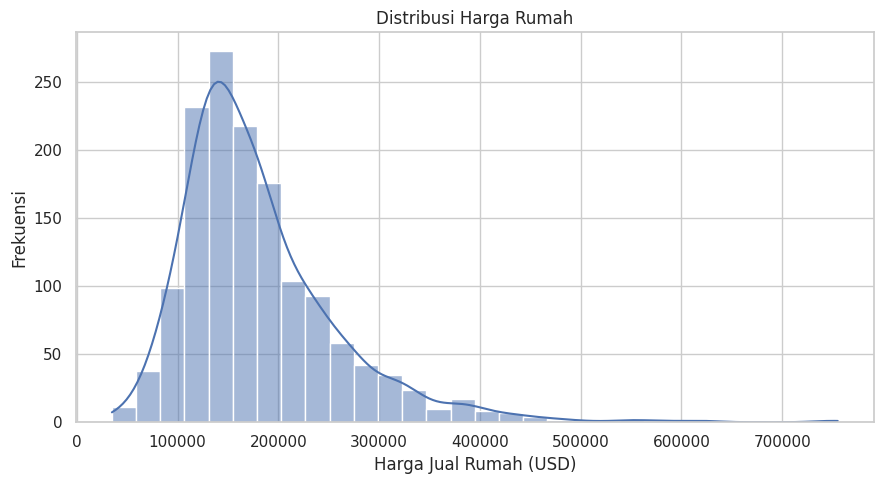

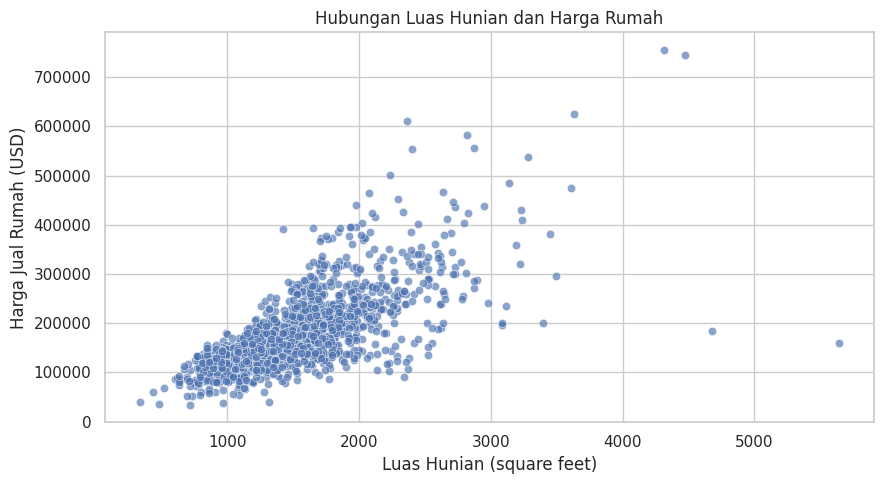

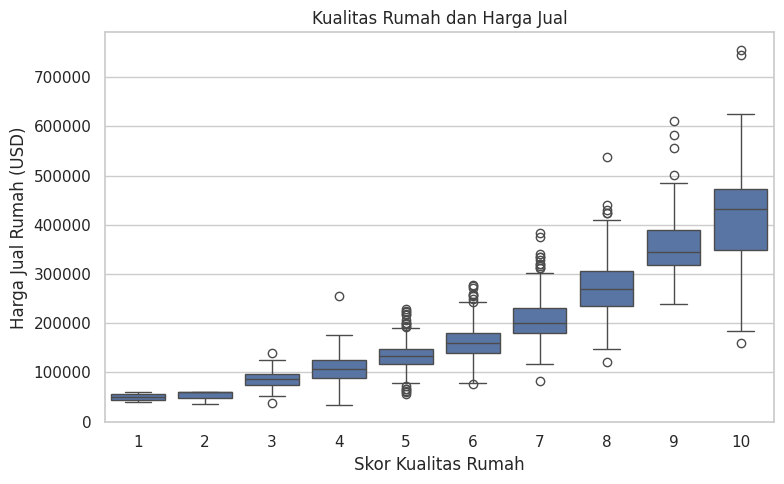

Fitur numerik yang berkorelasi dengan SalePrice:


,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


In [8]:
#202431113_Yanfa Nur Fadhlih
plt.figure(figsize=(9, 5))
sns.histplot(df["SalePrice"], bins=30, kde=True)
plt.title("Distribusi Harga Rumah")
plt.xlabel("Harga Jual Rumah (USD)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    alpha=0.65
)
plt.title("Hubungan Luas Hunian dan Harga Rumah")
plt.xlabel("Luas Hunian (square feet)")
plt.ylabel("Harga Jual Rumah (USD)")
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice")
plt.title("Kualitas Rumah dan Harga Jual")
plt.xlabel("Skor Kualitas Rumah")
plt.ylabel("Harga Jual Rumah (USD)")
plt.tight_layout()
plt.show()


corr = df.select_dtypes(include=np.number).corr()
top_corr = corr["SalePrice"].sort_values(ascending=False)

print("Fitur numerik yang berkorelasi dengan SalePrice:")
display(top_corr.head(12))


In [9]:
#202431113_Yanfa Nur Fadhlih
df = df.dropna(subset=["SalePrice"]).copy()


X = df.drop(columns=["SalePrice", "Id"], errors="ignore")
y = df["SalePrice"]

print("Jumlah sampel:", len(X))
print("Jumlah fitur sebelum preprocessing:", X.shape[1])
print("Target:", y.name)


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nData latih:", X_train.shape)
print("Data uji:", X_test.shape)


Jumlah sampel: 1460
Jumlah fitur sebelum preprocessing: 79
Target: SalePrice

Data latih: (1168, 79)
Data uji: (292, 79)


In [10]:
#202431113_Yanfa Nur Fadhlih
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()


numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])


categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])


model.fit(X_train, y_train)

print("Model berhasil dilatih.")


Model berhasil dilatih.


In [11]:
#202431113_Yanfa Nur Fadhlih
y_pred = model.predict(X_test)


mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("===== HASIL EVALUASI MODEL =====")
print(f"MAE  : ${mae:,.2f}")
print(f"RMSE : ${rmse:,.2f}")
print(f"R²   : {r2:.4f}")

hasil_evaluasi = pd.DataFrame({
    "Metrik": ["MAE", "RMSE", "R2"],
    "Nilai": [mae, rmse, r2]
})

display(hasil_evaluasi)


===== HASIL EVALUASI MODEL =====
MAE  : $17,525.45
RMSE : $28,835.69
R²   : 0.8916


,Metrik,Nilai
0,MAE,17525.451864
1,RMSE,28835.689063
2,R2,0.891596


,Harga_Aktual,Harga_Prediksi,Selisih_Absolut
0,154500,140734.893948,13765.106052
1,325000,322479.394484,2520.605516
2,115000,116398.903294,1398.903294
3,159000,154119.900675,4880.099325
4,315500,326586.997226,11086.997226
5,75500,85710.724048,10210.724048
6,311500,208740.430476,102759.569524
7,146000,150405.499214,4405.499214
8,84500,84854.260000,354.260000
9,135500,129232.482857,6267.517143


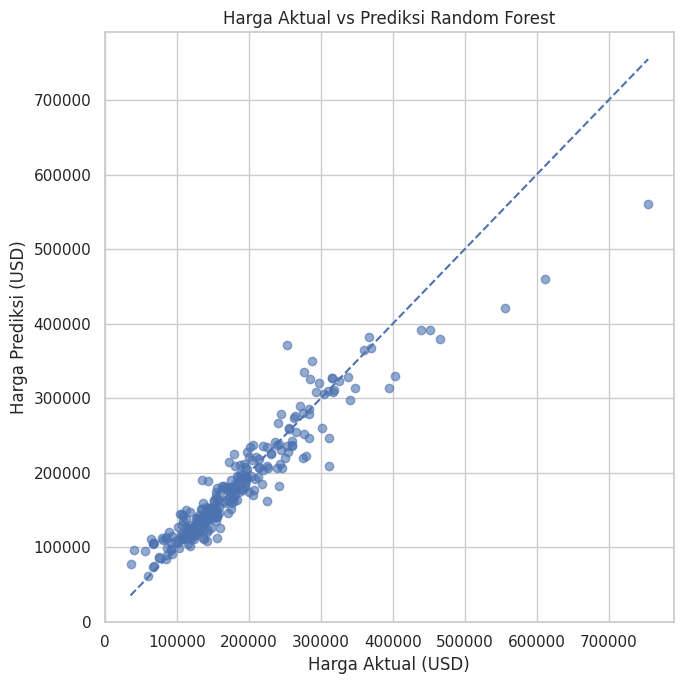

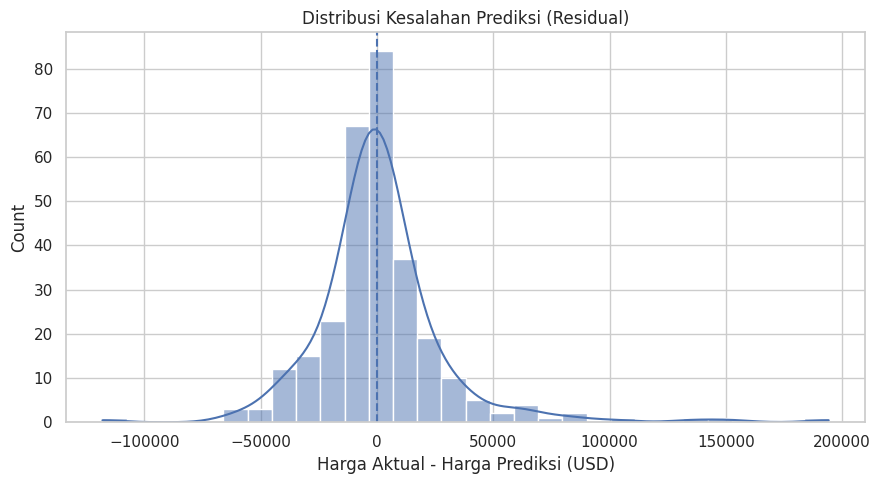

In [12]:
#202431113_Yanfa Nur Fadhlih
hasil_prediksi = pd.DataFrame({
    "Harga_Aktual": y_test.to_numpy(),
    "Harga_Prediksi": y_pred
})

hasil_prediksi["Selisih_Absolut"] = (
    hasil_prediksi["Harga_Aktual"]
    - hasil_prediksi["Harga_Prediksi"]
).abs()

display(hasil_prediksi.head(15))


plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.6)

batas_min = min(y_test.min(), y_pred.min())
batas_max = max(y_test.max(), y_pred.max())

plt.plot(
    [batas_min, batas_max],
    [batas_min, batas_max],
    linestyle="--"
)

plt.xlabel("Harga Aktual (USD)")
plt.ylabel("Harga Prediksi (USD)")
plt.title("Harga Aktual vs Prediksi Random Forest")
plt.tight_layout()
plt.show()


residual = y_test.to_numpy() - y_pred

plt.figure(figsize=(9, 5))
sns.histplot(residual, bins=30, kde=True)
plt.axvline(0, linestyle="--")
plt.title("Distribusi Kesalahan Prediksi (Residual)")
plt.xlabel("Harga Aktual - Harga Prediksi (USD)")
plt.tight_layout()
plt.show()


In [13]:
#202431113_Yanfa Nur Fadhlih
df.to_csv("/content/dataset_harga_rumah.csv", index=False)


hasil_prediksi.to_csv(
    "/content/hasil_prediksi.csv",
    index=False
)


hasil_evaluasi.to_csv(
    "/content/evaluasi_model.csv",
    index=False
)


joblib.dump(model, "/content/model_harga_rumah.joblib")

print("File berhasil disiapkan:")
print("- dataset_harga_rumah.csv")
print("- hasil_prediksi.csv")
print("- evaluasi_model.csv")
print("- model_harga_rumah.joblib")


File berhasil disiapkan:
- dataset_harga_rumah.csv
- hasil_prediksi.csv
- evaluasi_model.csv
- model_harga_rumah.joblib


In [14]:
#202431113_Yanfa Nur Fadhlih
files.download("/content/dataset_harga_rumah.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Fitur,Importance
3,num__OverallQual,0.562495
15,num__GrLivArea,0.124173
11,num__TotalBsmtSF,0.033849
13,num__2ndFlrSF,0.030748
8,num__BsmtFinSF1,0.027816
12,num__1stFlrSF,0.026679
2,num__LotArea,0.017910
26,num__GarageArea,0.015819
25,num__GarageCars,0.014373
5,num__YearBuilt,0.012135


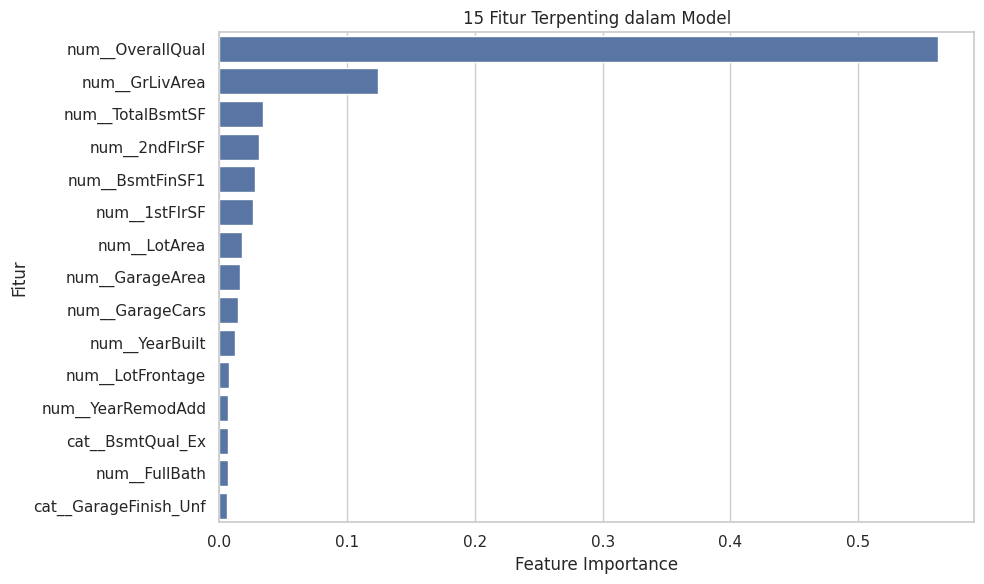

In [15]:
#202431113_Yanfa Nur Fadhlih
preprocessor_terlatih = model.named_steps["preprocessor"]
rf = model.named_steps["regressor"]

nama_fitur = preprocessor_terlatih.get_feature_names_out()
kepentingan = rf.feature_importances_

fitur_penting = pd.DataFrame({
    "Fitur": nama_fitur,
    "Importance": kepentingan
}).sort_values("Importance", ascending=False)

display(fitur_penting.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=fitur_penting.head(15),
    x="Importance",
    y="Fitur"
)
plt.title("15 Fitur Terpenting dalam Model")
plt.xlabel("Feature Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()
